
Weather data:
   City  Temperature_C  Humidity_pct  Pressure_hPa  Wind_Speed_mps
0  Pune          23.92            56          1015            1.05

Summary statistics:
       Temperature_C  Humidity_pct  Pressure_hPa  Wind_Speed_mps
count           1.00           1.0           1.0            1.00
mean           23.92          56.0        1015.0            1.05
std              NaN           NaN           NaN             NaN
min            23.92          56.0        1015.0            1.05
25%            23.92          56.0        1015.0            1.05
50%            23.92          56.0        1015.0            1.05
75%            23.92          56.0        1015.0            1.05
max            23.92          56.0        1015.0            1.05


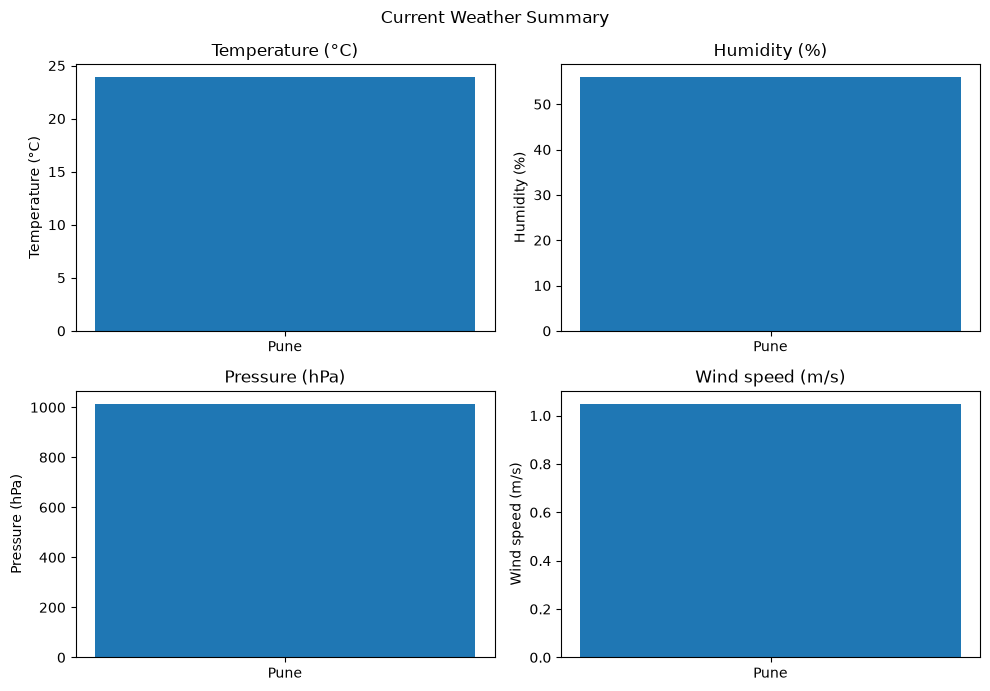

In [ ]:
import getpass
import requests
import pandas as pd
import matplotlib.pyplot as plt
# api key aaabf9bec00f6234648e6e8cfb0524e5
API_KEY = getpass.getpass("Enter your OpenWeatherMap API key: ").strip()
CITY = "Pune"

if not API_KEY:
    raise ValueError("No API key was entered.")

url = "https://api.openweathermap.org/data/2.5/weather"

try:
    response = requests.get(
        url,
        params={"q": CITY, "appid": API_KEY, "units": "metric"},
        timeout=20
    )

    if response.status_code == 401:
        raise ValueError(
            "OpenWeatherMap rejected the key. Check that it is correct and "
            "activated; a new key can take up to two hours to start working."
        )

    if response.status_code == 404:
        raise ValueError(f"City not found: {CITY}")

    response.raise_for_status()
    data = response.json()

except requests.exceptions.RequestException as error:
    raise SystemExit(f"Could not retrieve weather data: {error}")

record = {
    "City": data["name"],
    "Temperature_C": data["main"]["temp"],
    "Humidity_pct": data["main"]["humidity"],
    "Pressure_hPa": data["main"]["pressure"],
    "Wind_Speed_mps": data.get("wind", {}).get("speed")
}

df = pd.DataFrame([record])

print("\nWeather data:")
print(df)

weather_columns = [
    "Temperature_C",
    "Humidity_pct",
    "Pressure_hPa",
    "Wind_Speed_mps"
]

print("\nSummary statistics:")
print(df[weather_columns].describe())

df.to_csv("weather_data.csv", index=False)

chart_details = [
    ("Temperature_C", "Temperature (°C)"),
    ("Humidity_pct", "Humidity (%)"),
    ("Pressure_hPa", "Pressure (hPa)"),
    ("Wind_Speed_mps", "Wind speed (m/s)")
]

fig, axes = plt.subplots(2, 2, figsize=(10, 7))

for ax, (column, label) in zip(axes.flat, chart_details):
    ax.bar(df["City"], df[column])
    ax.set_title(label)
    ax.set_ylabel(label)

fig.suptitle("Current Weather Summary")
plt.tight_layout()
plt.show()